# Data preparation

Load the survey, select valid responses, and combine Hong Kong with China. Define honesty importance and the outcome `C_minus_B = E33 - E32`, where higher values mean a more favorable evaluation of the reporter relative to the student permitting copying. All regressions use HC3 robust standard errors.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import pyreadstat
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from IPython.display import display

sav_path = Path.cwd() / "data_combined_20.08.2026.sav"
columns = ["imp3", "E31", "E32", "E33", "cntry", "age", "gender", "degree", "PDI1", "IDV"]
df, meta = pyreadstat.read_sav(
    str(sav_path), usecols=columns, apply_value_formats=False, user_missing=True
)

valid = (
    df[["imp3", "E31", "E32", "E33"]].isin([1, 2, 3, 4, 5]).all(axis=1)
    & df["age"].between(16, 100)
    & df["cntry"].isin(range(1, 10))
    & df["gender"].isin([1, 2, 3])
    & df["degree"].isin([1, 2, 3, 4, 5])
)
analysis = df.loc[valid].copy()
# Pool Hong Kong with China in the analysis; retain original codes in df.
analysis["cntry"] = analysis["cntry"].replace({7: 4})
country_labels = meta.variable_value_labels["cntry"].copy()
country_labels[4] = "China (incl. Hong Kong)"
country_labels.pop(7, None)
analysis["honesty_importance"] = analysis["imp3"]
analysis["C_minus_B"] = analysis["E33"] - analysis["E32"]
analysis["region"] = np.where(analysis["cntry"].isin([1, 2, 9]), "Western", "Eastern")
for variable in ["cntry", "gender", "degree"]:
    analysis[variable] = analysis[variable].astype(int).astype("category")

print(f"Common regression sample: {len(analysis):,} of {len(df):,} rows "
      f"({len(df) - len(analysis):,} excluded by validity / complete-case rules).")

Common regression sample: 2,734 of 7,194 rows (4,460 excluded by validity / complete-case rules).


## Regression tables and plots

Define a shared format for coefficient tables, significance marks, confidence intervals, and plots. Points show respondents, while the fitted line shows adjusted model predictions.

In [2]:
# Shared presentation; each regression is fitted in its own cell below.
def show_regression(result, title, sample=None, predictors=None, country_lines=False):
    if sample is None:
        sample = analysis
    if predictors is None:
        predictors = ["honesty_importance"]

    ci = result.conf_int()
    table = pd.DataFrame({
        "beta": result.params,
        "HC3 SE": result.bse,
        "p-value": result.pvalues,
        "95% CI lower": ci[0],
        "95% CI upper": ci[1],
    })
    table["significance"] = pd.cut(
        table["p-value"], bins=[-np.inf, .001, .01, .05, .10, np.inf],
        labels=["***", "**", "*", ".", ""], right=False
    )
    table = table.rename(index={
        "PDI1": "Power distance (PDI1)", "IDV": "Individualism (IDV)"
    })
    print(title)
    print(f"N = {int(result.nobs):,} | R² = {result.rsquared:.3f} | "
          f"Adjusted R² = {result.rsquared_adj:.3f} | Standard errors: {result.cov_type}")
    display(table.style.format({
        "beta": "{:.4f}", "HC3 SE": "{:.4f}", "p-value": "{:.3g}",
        "95% CI lower": "{:.4f}", "95% CI upper": "{:.4f}"
    }))

    for predictor in predictors:
        if predictor == "honesty_importance":
            levels = np.arange(1, 6)
            ticks = levels
            xlabel = "Honesty importance (1 = least, 5 = very important)"
            xlim = (.7, 5.3)
            jitter_width = .12
        else:
            # Limit the fitted line to the observed score range.
            levels = np.linspace(sample[predictor].min(), sample[predictor].max(), 40)
            ticks = [1, 2, 3, 4]
            xlabel = "Rejection of dishonesty (ten-item mean; 4 = strongest rejection of dishonesty)"
            xlim = (.8, 4.2)
            jitter_width = .025

        rng = np.random.default_rng(42)
        plot_x = sample[predictor].to_numpy() + rng.uniform(-jitter_width, jitter_width, len(sample))
        plot_y = sample["C_minus_B"].to_numpy() + rng.uniform(-.10, .10, len(sample))
        fig, ax = plt.subplots(figsize=(8, 5))
        for region, color in [("Western", "blue"), ("Eastern", "red")]:
            mask = sample["region"].eq(region).to_numpy()
            ax.scatter(plot_x[mask], plot_y[mask], color=color, s=13, alpha=.18,
                       edgecolors="none", label=region)
        mean_predictions = [
            result.predict(sample.assign(**{predictor: level})).mean()
            for level in levels
        ]
        ax.plot(levels, mean_predictions, color="black", linewidth=2.5,
                label="Model mean prediction", zorder=3)
        if country_lines and predictor == "honest_behavior":
            line_styles = ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1))]
            for i, country in enumerate(sample["cntry"].cat.categories):
                country_sample = sample.loc[sample["cntry"].eq(country)]
                if country_sample.empty:
                    continue
                country_levels = np.linspace(
                    country_sample[predictor].min(), country_sample[predictor].max(), 30
                )
                predictions = [
                    result.predict(country_sample.assign(**{predictor: level})).mean()
                    for level in country_levels
                ]
                color = "blue" if country in [1, 2, 9] else "red"
                ax.plot(country_levels, predictions, color=color,
                        linestyle=line_styles[i % len(line_styles)], linewidth=1.8,
                        label=country_labels[country])
        ax.axhline(0, color="gray", linestyle="--", linewidth=1)
        ax.set(xlabel=xlabel,
               ylabel="C_minus_B (reporter − student permitting copying)",
               title=title, xticks=ticks, yticks=range(-4, 5),
               xlim=xlim, ylim=(-4.3, 4.3))
        if country_lines and predictor == "honest_behavior":
            ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
        else:
            ax.legend()
        fig.tight_layout()
        plt.show()
        plt.close(fig)

## Model 1: honesty importance

Estimate the association between honesty importance and relative evaluation of the reporter.

Model 1: honesty importance
N = 2,734 | R² = 0.000 | Adjusted R² = -0.000 | Standard errors: HC3


,beta,HC3 SE,p-value,95% CI lower,95% CI upper,significance
Intercept,0.1428,0.1169,0.222,-0.0864,0.3720,
honesty_importance,-0.0224,0.0286,0.433,-0.0784,0.0336,


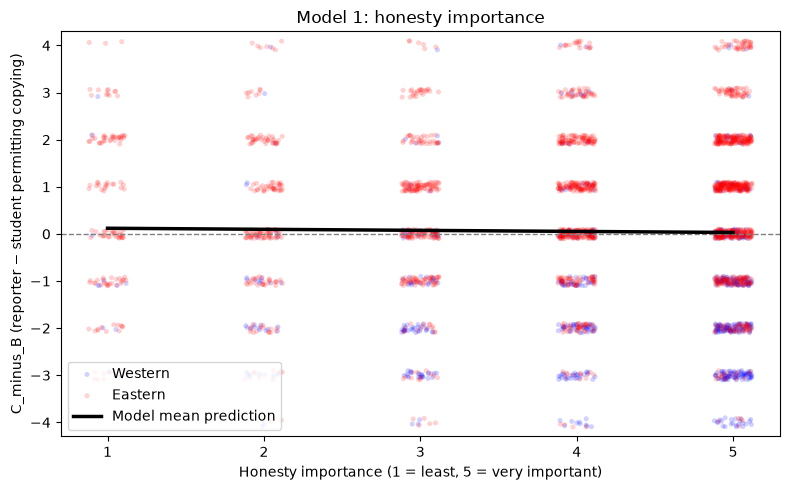

In [3]:
model_1 = smf.ols(
    "C_minus_B ~ honesty_importance", data=analysis, missing="raise"
).fit(cov_type="HC3")
show_regression(model_1, "Model 1: honesty importance")

## Model 2: country controls

Add country fixed effects to account for differences in evaluation levels across countries.

Model 2: honesty importance + country fixed effects
N = 2,734 | R² = 0.211 | Adjusted R² = 0.209 | Standard errors: HC3


,beta,HC3 SE,p-value,95% CI lower,95% CI upper,significance
Intercept,-1.6152,0.1411,2.36e-30,-1.8917,-1.3387,***
C(cntry)[T.2],0.2044,0.2112,0.333,-0.2096,0.6184,
C(cntry)[T.3],2.0064,0.0878,1.89e-115,1.8342,2.1786,***
C(cntry)[T.4],1.7687,0.0940,4.76e-79,1.5846,1.9529,***
C(cntry)[T.5],1.7675,0.0937,2.53e-79,1.5838,1.9512,***
C(cntry)[T.6],2.4065,0.1739,1.52e-43,2.0656,2.7473,***
C(cntry)[T.8],1.8178,0.1607,1.14e-29,1.5029,2.1328,***
honesty_importance,0.0670,0.0295,0.0232,0.0092,0.1248,*


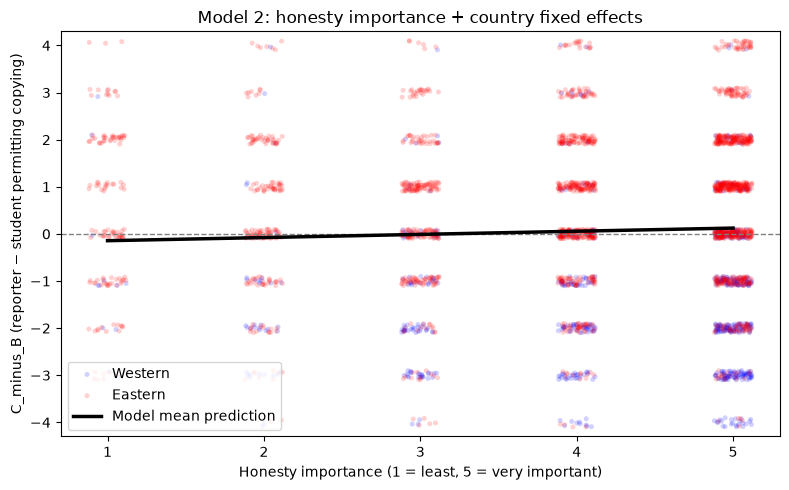

In [4]:
model_2 = smf.ols(
    "C_minus_B ~ honesty_importance + C(cntry)", data=analysis, missing="raise"
).fit(cov_type="HC3")
show_regression(model_2, "Model 2: honesty importance + country fixed effects")

## Model 3: demographic controls

Add age, gender, and education to the honesty-importance and country model.

Model 3: country fixed effects + demographic controls
N = 2,734 | R² = 0.218 | Adjusted R² = 0.214 | Standard errors: HC3


,beta,HC3 SE,p-value,95% CI lower,95% CI upper,significance
Intercept,-2.0075,0.1989,5.97e-24,-2.3974,-1.6176,***
C(cntry)[T.2],0.2417,0.2091,0.248,-0.1682,0.6516,
C(cntry)[T.3],1.9419,0.0973,1.4e-88,1.7512,2.1327,***
C(cntry)[T.4],1.7591,0.1006,2.04e-68,1.5619,1.9564,***
C(cntry)[T.5],1.7962,0.0951,1.54e-79,1.6098,1.9826,***
C(cntry)[T.6],2.4513,0.1772,1.53e-43,2.1041,2.7985,***
C(cntry)[T.8],1.8336,0.1629,2.14e-29,1.5143,2.1528,***
C(gender)[T.2],0.1051,0.0641,0.101,-0.0205,0.2306,
C(gender)[T.3],0.3881,0.4976,0.435,-0.5872,1.3635,
C(degree)[T.2],0.0748,0.0767,0.329,-0.0755,0.2251,


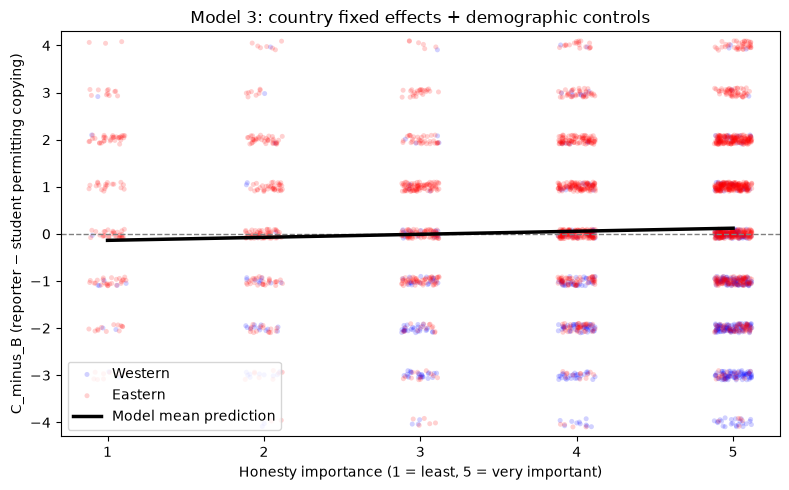

In [5]:
model_3 = smf.ols(
    "C_minus_B ~ honesty_importance + C(cntry) + age + C(gender) + C(degree)",
    data=analysis, missing="raise"
).fit(cov_type="HC3")
show_regression(model_3, "Model 3: country fixed effects + demographic controls")

## Rejection of dishonesty: ten survey items

Use all ten E5 questions, including E52 and E510, to measure rejection of dishonest actions.

### Response distributions and Cronbach’s alpha

Show response counts and percentages, then calculate Cronbach’s alpha to assess internal consistency. Keep responses from 1 to 4, treat other responses as missing, and require valid answers to all ten questions.

In [6]:
e5_items = [f"E5{i}" for i in range(1, 11)]
e5_raw, e5_meta = pyreadstat.read_sav(
    str(sav_path), usecols=e5_items, apply_value_formats=False, user_missing=True
)
# Row indices refer to the same source file loaded above.
e5_sample = e5_raw.loc[analysis.index].copy()
item_names = {
    "E51": "Buying stolen goods",
    "E52": "Keeping money found in the street",
    "E53": "Having an affair while married",
    "E54": "Not reporting damage to a parked vehicle",
    "E55": "Fare evasion",
    "E56": "Tax cheating",
    "E57": "Accepting a bribe",
    "E58": "Fabricating a job application",
    "E59": "Promising a child a reward that will not be given",
    "E510": "Lying about a dangerous wolf to keep a child out of the forest",
}
response_labels = {
    1: "1 Always justified", 2: "2 Sometimes justified",
    3: "3 Rarely justified", 4: "4 Never justified", 5: "5 Don't know"
}

response_counts = pd.DataFrame({
    label: e5_sample.eq(value).sum() for value, label in response_labels.items()
})
response_counts["Missing"] = e5_sample.isna().sum()
response_counts["Invalid code"] = (
    e5_sample.notna() & ~e5_sample.isin([1, 2, 3, 4, 5])
).sum()
response_percent = 100 * response_counts / len(e5_sample)
response_table = response_counts.copy().astype(str)
for column in response_counts:
    response_table[column] = [
        f"{count:,} ({percent:.1f}%)"
        for count, percent in zip(response_counts[column], response_percent[column])
    ]
response_table.insert(0, "Question", pd.Series(item_names))
response_table.index.name = "Item"
print(f"Response table denominator: {len(e5_sample):,} regression-sample respondents per row.")
with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
    display(response_table)

# Raw Cronbach's alpha: k/(k-1) * (1 - sum(item variances)/variance(total)).
e5_valid = e5_sample.where(e5_sample.isin([1, 2, 3, 4]))
e5_complete = e5_valid.dropna()
k = len(e5_items)
if len(e5_complete) < 2:
    raise ValueError("Too few complete respondents to estimate Cronbach's alpha.")
item_variances = e5_complete.var(ddof=1)
total_variance = e5_complete.sum(axis=1).var(ddof=1)
if total_variance <= 0:
    raise ValueError("Cronbach's alpha is undefined: total scores have no variance.")
cronbach_alpha = k / (k - 1) * (1 - item_variances.sum() / total_variance)
alpha_summary = pd.DataFrame({
    "Items": [k],
    "Starting sample N": [len(e5_sample)],
    "Complete ten-item N": [len(e5_complete)],
    "Excluded for missing / don't know / invalid": [len(e5_sample) - len(e5_complete)],
    "Cronbach's alpha": [cronbach_alpha],
})
display(alpha_summary.style.format({"Cronbach's alpha": "{:.3f}"}))
print(f"Cronbach's alpha = {cronbach_alpha:.3f}; N = {len(e5_complete):,} complete respondents.")

Response table denominator: 2,734 regression-sample respondents per row.


,Question,1 Always justified,2 Sometimes justified,3 Rarely justified,4 Never justified,5 Don't know,Missing,Invalid code
Item,,,,,,,,
E51,Buying stolen goods,43 (1.6%),448 (16.4%),740 (27.1%),"1,454 (53.2%)",47 (1.7%),2 (0.1%),0 (0.0%)
E52,Keeping money found in the street,185 (6.8%),"1,032 (37.7%)",747 (27.3%),721 (26.4%),41 (1.5%),8 (0.3%),0 (0.0%)
E53,Having an affair while married,37 (1.4%),248 (9.1%),540 (19.8%),"1,829 (66.9%)",76 (2.8%),4 (0.1%),0 (0.0%)
E54,Not reporting damage to a parked vehicle,57 (2.1%),328 (12.0%),857 (31.3%),"1,438 (52.6%)",45 (1.6%),8 (0.3%),1 (0.0%)
E55,Fare evasion,86 (3.1%),514 (18.8%),761 (27.8%),"1,331 (48.7%)",36 (1.3%),5 (0.2%),1 (0.0%)
E56,Tax cheating,79 (2.9%),324 (11.9%),627 (22.9%),"1,637 (59.9%)",57 (2.1%),8 (0.3%),2 (0.1%)
E57,Accepting a bribe,30 (1.1%),199 (7.3%),483 (17.7%),"1,972 (72.1%)",47 (1.7%),3 (0.1%),0 (0.0%)
E58,Fabricating a job application,57 (2.1%),515 (18.8%),778 (28.5%),"1,333 (48.8%)",44 (1.6%),6 (0.2%),1 (0.0%)
E59,Promising a child a reward that will not be given,54 (2.0%),472 (17.3%),797 (29.2%),"1,365 (49.9%)",44 (1.6%),2 (0.1%),0 (0.0%)


,Items,Starting sample N,Complete ten-item N,Excluded for missing / don't know / invalid,Cronbach's alpha
0,10,2734,2390,344,0.719


Cronbach's alpha = 0.719; N = 2,390 complete respondents.


## Model 4: rejection of dishonesty

Average all ten items to create `honest_behavior`, where higher scores indicate stronger rejection of dishonest actions. Add this score to Model 3 using respondents with complete answers to all ten items.

Model 4 sample: 2,390; 344 fewer respondents than Model 3.
Model 4: both honesty measures + country and demographic controls
N = 2,390 | R² = 0.249 | Adjusted R² = 0.244 | Standard errors: HC3


,beta,HC3 SE,p-value,95% CI lower,95% CI upper,significance
Intercept,-3.8916,0.3255,6.05e-33,-4.5296,-3.2537,***
C(cntry)[T.2],0.5510,0.2146,0.0102,0.1304,0.9717,*
C(cntry)[T.3],1.8799,0.1027,6.54e-75,1.6787,2.0811,***
C(cntry)[T.4],1.6785,0.1077,8.54e-55,1.4674,1.8895,***
C(cntry)[T.5],1.8086,0.1029,4.13e-69,1.6069,2.0103,***
C(cntry)[T.6],2.4258,0.1844,1.52e-39,2.0645,2.7871,***
C(cntry)[T.8],1.7472,0.1839,2.07e-21,1.3868,2.1077,***
C(gender)[T.2],0.1050,0.0674,0.119,-0.0271,0.2371,
C(gender)[T.3],0.6081,0.6350,0.338,-0.6365,1.8528,
C(degree)[T.2],0.0934,0.0825,0.258,-0.0684,0.2552,


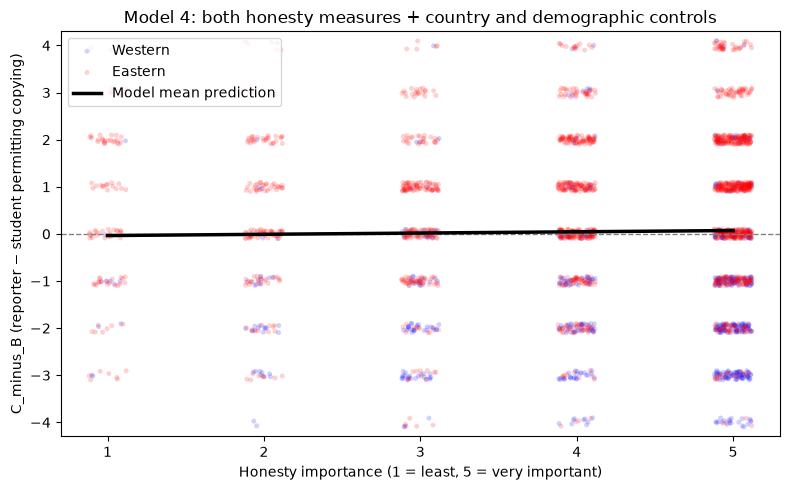

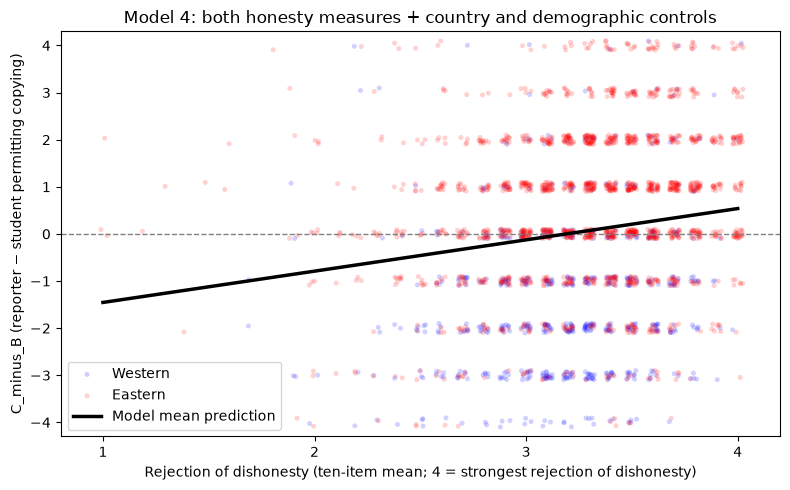

In [7]:
analysis_4 = analysis.loc[e5_complete.index].copy()
analysis_4["honest_behavior"] = e5_complete.mean(axis=1)
print(f"Model 4 sample: {len(analysis_4):,}; "
      f"{len(analysis) - len(analysis_4):,} fewer respondents than Model 3.")

model_4 = smf.ols(
    "C_minus_B ~ honesty_importance + honest_behavior + C(cntry) + age + C(gender) + C(degree)",
    data=analysis_4, missing="raise"
).fit(cov_type="HC3")
show_regression(
    model_4, "Model 4: both honesty measures + country and demographic controls",
    sample=analysis_4, predictors=["honesty_importance", "honest_behavior"]
)

## Model 5: power distance and individualism

Add the existing power-distance index `PDI1` and individualism index `IDV` to Model 4. Retain their original units and use respondents with both indices available.

Model 5 sample: 2,217; 173 fewer respondents than Model 4.
Countries lost relative to Model 4: ['India']
Model 5: add power distance and individualism
N = 2,217 | R² = 0.273 | Adjusted R² = 0.267 | Standard errors: HC3


,beta,HC3 SE,p-value,95% CI lower,95% CI upper,significance
Intercept,-3.7999,0.3489,1.28e-27,-4.4838,-3.1160,***
C(cntry)[T.2],0.5511,0.2091,0.00842,0.1411,0.9610,**
C(cntry)[T.3],1.7765,0.1074,1.69e-61,1.5661,1.9869,***
C(cntry)[T.4],1.6079,0.1111,1.68e-47,1.3903,1.8256,***
C(cntry)[T.5],1.8277,0.1022,1.61e-71,1.6274,2.0280,***
C(cntry)[T.6],2.3411,0.1884,1.89e-35,1.9719,2.7104,***
C(gender)[T.2],0.0696,0.0696,0.317,-0.0668,0.2059,
C(gender)[T.3],0.5522,0.6196,0.373,-0.6623,1.7666,
C(degree)[T.2],0.1057,0.0841,0.209,-0.0591,0.2705,
C(degree)[T.3],0.3990,0.1211,0.000988,0.1616,0.6365,***


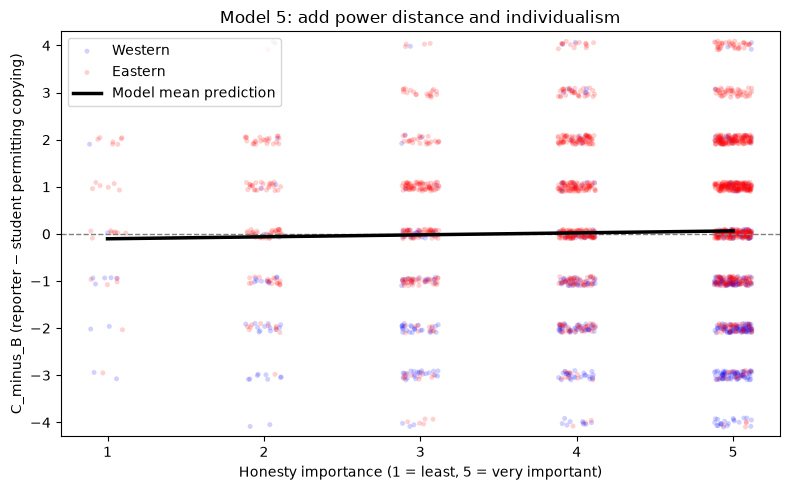

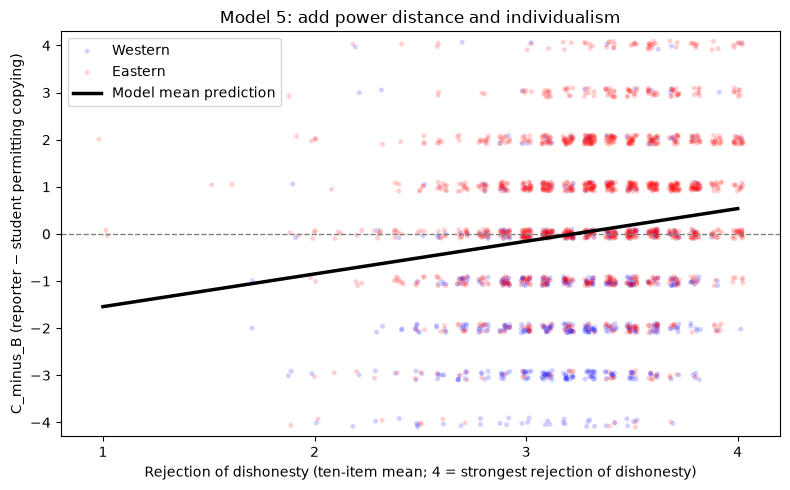

In [8]:
# Retain the existing index units; require both additional controls for Model 5 only.
analysis_5 = analysis_4.loc[
    np.isfinite(analysis_4[["PDI1", "IDV"]]).all(axis=1)
].copy()
for variable in ["cntry", "gender", "degree"]:
    analysis_5[variable] = analysis_5[variable].cat.remove_unused_categories()

print(f"Model 5 sample: {len(analysis_5):,}; "
      f"{len(analysis_4) - len(analysis_5):,} fewer respondents than Model 4.")
absent_countries = sorted(set(analysis_4["cntry"]) - set(analysis_5["cntry"]))
print("Countries lost relative to Model 4:",
      [country_labels[code] for code in absent_countries] or "None")

model_5 = smf.ols(
    "C_minus_B ~ honesty_importance + honest_behavior + C(cntry) "
    "+ age + C(gender) + C(degree) + PDI1 + IDV",
    data=analysis_5, missing="raise"
).fit(cov_type="HC3")

show_regression(
    model_5, "Model 5: add power distance and individualism",
    sample=analysis_5, predictors=["honesty_importance", "honest_behavior"]
)

## Models 1–5: coefficient comparison

Compare all five models side by side using readable variable names, significance marks, and HC3 standard errors. Include sample sizes and model fit statistics; Models 4 and 5 can use fewer respondents because of their additional data requirements.

In [9]:
import re

comparison_models = {
    "Model 1": model_1, "Model 2": model_2,
    "Model 3": model_3, "Model 4": model_4,
    "Model 5": model_5,
}


def significance_mark(p):
    if p < .001:
        return "***"
    if p < .01:
        return "**"
    if p < .05:
        return "*"
    if p < .10:
        return "·"
    return ""


def readable_term(term):
    names = {
        "Intercept": "Intercept",
        "honesty_importance": "Honesty importance",
        "honest_behavior": "Rejection of dishonesty",
        "age": "Age (years)",
        "PDI1": "Power distance (PDI1)",
        "IDV": "Individualism (IDV)",
    }
    if term in names:
        return names[term]
    match = re.fullmatch(r"C\((cntry|gender|degree)\)\[T\.(\d+)\]", term)
    if match:
        variable, code = match.groups()
        labels = country_labels if variable == "cntry" else meta.variable_value_labels[variable]
        label = labels[int(code)]
        prefix = {"cntry": "", "gender": "Gender: ", "degree": "Education: "}[variable]
        return prefix + label
    return term

# Lead with the research variables, then show all other coefficients.
all_terms = list(dict.fromkeys(
    term for model in comparison_models.values() for term in model.params.index
))
term_order = ["honesty_importance", "honest_behavior", "PDI1", "IDV"] + [
    term for term in all_terms if term not in ["honesty_importance", "honest_behavior", "PDI1", "IDV", "Intercept"]
] + ["Intercept"]
comparison_table = pd.DataFrame(index=term_order, columns=comparison_models, dtype=object)
for name, model in comparison_models.items():
    for term in term_order:
        comparison_table.loc[term, name] = (
            f"{model.params[term]:.3f}{significance_mark(model.pvalues[term])} "
            f"({model.bse[term]:.3f})" if term in model.params else "—"
        )
comparison_table.index = [readable_term(term) for term in term_order]
for name, model in comparison_models.items():
    comparison_table.loc["Observations", name] = f"{int(model.nobs):,}"
    comparison_table.loc["R²", name] = f"{model.rsquared:.3f}"
    comparison_table.loc["Adjusted R²", name] = f"{model.rsquared_adj:.3f}"
comparison_table.index.name = "Predictor / statistic"

display(
    comparison_table.style
    .set_caption("Models 1–5 | beta with significance marks (HC3 standard error)")
    .set_properties(**{"text-align": "center", "padding": "9px 14px"})
    .set_table_styles([
        {"selector": "caption", "props": [("font-size", "17px"), ("font-weight", "bold"), ("text-align", "left")]},
        {"selector": "th", "props": [("text-align", "left"), ("padding", "9px 14px")]},
        {"selector": "thead th", "props": [("background-color", "#edf2f7"), ("color", "#172b4d")]},
    ])
)

,Model 1,Model 2,Model 3,Model 4,Model 5
Predictor / statistic,,,,,
Honesty importance,-0.022 (0.029),0.067* (0.029),0.064* (0.029),0.027 (0.030),0.042 (0.031)
Rejection of dishonesty,—,—,—,0.664*** (0.085),0.694*** (0.089)
Power distance (PDI1),—,—,—,—,0.001 (0.001)
Individualism (IDV),—,—,—,—,-0.003*** (0.001)
Estonia,—,0.204 (0.211),0.242 (0.209),0.551* (0.215),0.551** (0.209)
Taiwan,—,2.006*** (0.088),1.942*** (0.097),1.880*** (0.103),1.776*** (0.107)
China (incl. Hong Kong),—,1.769*** (0.094),1.759*** (0.101),1.678*** (0.108),1.608*** (0.111)
Vietnam,—,1.767*** (0.094),1.796*** (0.095),1.809*** (0.103),1.828*** (0.102)
Japan,—,2.406*** (0.174),2.451*** (0.177),2.426*** (0.184),2.341*** (0.188)


## Presentation plots: Model 5

Plot rejection of dishonesty against relative reporter evaluation, with Model 5’s adjusted prediction line. Show Model 5’s adjusted country differences from Germany with 95% confidence intervals. Save both figures as PNG and PDF files in `presentation_figures`.

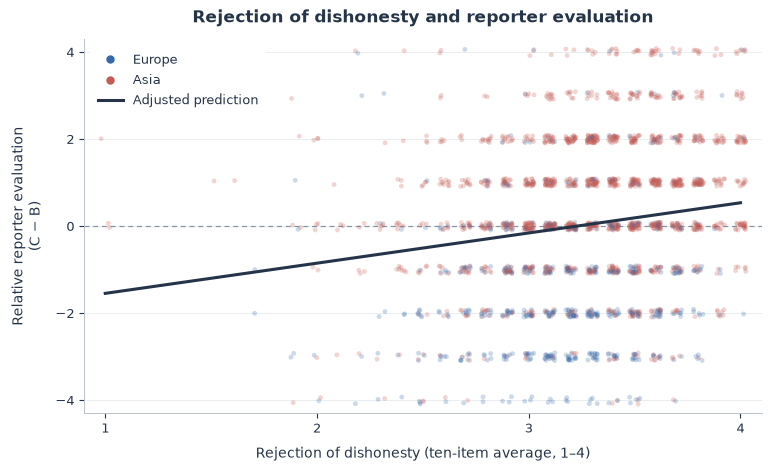

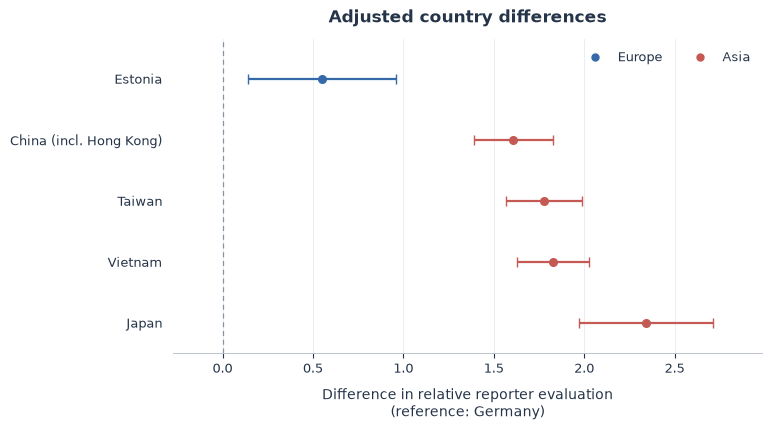

In [12]:
from matplotlib.lines import Line2D
import re

figure_dir = Path("presentation_figures")
figure_dir.mkdir(exist_ok=True)
blue, red, ink = "#3569A8", "#C45A53", "#253449"
report_style = {
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.labelsize": 10,
    "axes.labelpad": 8,
    "axes.edgecolor": "#BBC3CC",
    "axes.linewidth": .7,
    "text.color": ink,
    "axes.labelcolor": ink,
    "xtick.color": ink,
    "ytick.color": ink,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}


def save_report_figure(fig, filename):
    # Use the PDF in Overleaf; the PNG is a high-resolution alternative.
    for extension in ["pdf", "png"]:
        path = figure_dir / f"{filename}.{extension}"
        fig.savefig(path, dpi=300, bbox_inches="tight", pad_inches=.08,
                    facecolor="white")


with plt.rc_context(report_style):
    # Figure 1: raw responses and the Model 5 adjusted prediction.
    fig, ax = plt.subplots(figsize=(7.6, 4.6), layout="constrained")
    rng = np.random.default_rng(42)
    x = analysis_5["honest_behavior"].to_numpy()
    y = analysis_5["C_minus_B"].to_numpy()
    jitter_x = x + rng.uniform(-.025, .025, len(x))
    jitter_y = y + rng.uniform(-.09, .09, len(y))
    order = rng.permutation(len(analysis_5))
    colors = np.where(analysis_5["region"].eq("Western"), blue, red)
    ax.scatter(jitter_x[order], jitter_y[order], c=colors[order],
               s=12, alpha=.25, edgecolors="none", rasterized=True, zorder=2)

    levels = np.linspace(x.min(), x.max(), 100)
    predictions = [
        model_5.predict(analysis_5.assign(honest_behavior=level)).mean()
        for level in levels
    ]
    ax.plot(levels, predictions, color=ink, linewidth=2.2, zorder=4)
    ax.axhline(0, color="#8793A1", linestyle=(0, (4, 3)), linewidth=.9, zorder=1)
    ax.set(
        title="Rejection of dishonesty and reporter evaluation",
        xlabel="Rejection of dishonesty (ten-item average, 1–4)",
        ylabel="Relative reporter evaluation\n(C − B)",
        xlim=(.9, 4.1), ylim=(-4.3, 4.3),
        xticks=[1, 2, 3, 4], yticks=[-4, -2, 0, 2, 4],
    )
    ax.set_title(ax.get_title(), loc="center", pad=12)
    ax.grid(axis="y", color="#E7EBEF", linewidth=.6)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    # In the Model 5 sample, the Western/Eastern groups are Europe/Asia.
    ax.legend(handles=[
        Line2D([0], [0], marker="o", color=blue, linestyle="none",
               markersize=5, label="Europe"),
        Line2D([0], [0], marker="o", color=red, linestyle="none",
               markersize=5, label="Asia"),
        Line2D([0], [0], color=ink, linewidth=2.2,
               label="Adjusted prediction"),
    ], loc="upper left", fontsize=9, frameon=True, facecolor="white",
       edgecolor="none", framealpha=.95, borderpad=.6)
    save_report_figure(fig, "honesty_associations_model5")
    plt.show()
    plt.close(fig)

    # Figure 2: Model 5 country coefficients and pointwise 95% HC3 intervals.
    country_terms = sorted(
        [term for term in model_5.params.index if term.startswith("C(cntry)")],
        key=lambda term: model_5.params[term],
    )
    fig, ax = plt.subplots(figsize=(7.6, 4.2), layout="constrained")
    row_labels = []
    for row, term in enumerate(country_terms):
        code = int(re.search(r"T\.(\d+)", term).group(1))
        beta = model_5.params[term]
        lower, upper = model_5.conf_int().loc[term]
        row_labels.append(country_labels[code])
        ax.errorbar(
            beta, row, xerr=[[beta - lower], [upper - beta]],
            fmt="o", color=blue if code in [1, 2, 9] else red,
            markersize=5.5, capsize=3.5, linewidth=1.6, zorder=3,
        )
    ax.set_yticks(range(len(row_labels)), row_labels)
    ax.set_ylim(len(row_labels) - .5, -.65)
    ax.set_title("Adjusted country differences", pad=12)
    ax.set_xlabel("Difference in relative reporter evaluation\n(reference: Germany)")
    ax.axvline(0, color="#8793A1", linestyle=(0, (4, 3)), linewidth=.9)
    ax.grid(axis="x", color="#E7EBEF", linewidth=.6)
    ax.set_axisbelow(True)
    ax.margins(x=.10)
    ax.tick_params(axis="y", length=0, pad=8)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.legend(handles=[
        Line2D([0], [0], marker="o", color=blue, linestyle="none",
               markersize=5, label="Europe"),
        Line2D([0], [0], marker="o", color=red, linestyle="none",
               markersize=5, label="Asia"),
    ], loc="upper right", ncol=2, frameon=False, fontsize=9)
    save_report_figure(fig, "country_differences_model5")
    plt.show()
    plt.close(fig)


## Regional analysis: Europe and Asia

Estimate Model 5 without country dummies separately for Europe and Asia, including power distance and individualism. Use Model 5’s eligible sample with Hong Kong pooled with China; India drops out because its index values are missing. Compare regional coefficients and confidence intervals, noting that different significance levels alone do not establish different slopes.

In [13]:
regional_formula = (
    "C_minus_B ~ honesty_importance + honest_behavior + age + C(gender) + C(degree) + PDI1 + IDV"
)
regional_codes = {"Europe": [1, 2], "Asia": [3, 4, 5, 6, 8]}
regional_samples = {}
regional_models = {}

for region, codes in regional_codes.items():
    sample = analysis_5.loc[analysis_5["cntry"].isin(codes)].copy()
    # Avoid empty-category coefficients after splitting the sample.
    for variable in ["gender", "degree"]:
        sample[variable] = sample[variable].cat.remove_unused_categories()
    regional_samples[region] = sample
    regional_models[region] = smf.ols(
        regional_formula, data=sample, missing="raise"
    ).fit(cov_type="HC3")
    country_counts = sample["cntry"].value_counts().sort_index()
    coverage = ", ".join(
        f"{country_labels[code]}: {int(count):,}"
        for code, count in country_counts.items() if count > 0
    )
    references = ", ".join(
        f"{variable} = {meta.variable_value_labels[variable][sample[variable].cat.categories[0]]}"
        for variable in ["gender", "degree"]
    )
    print(f"{region}: N = {len(sample):,} ({coverage})")
    print(f"Reference groups: {references}")

regional_terms = list(dict.fromkeys(
    term for model in regional_models.values() for term in model.params.index
))
regional_order = ["honesty_importance", "honest_behavior", "PDI1", "IDV", "age"] + [
    term for term in regional_terms
    if term not in ["honesty_importance", "honest_behavior", "PDI1", "IDV", "age", "Intercept"]
] + ["Intercept"]
regional_table = pd.DataFrame(index=regional_order, columns=regional_models, dtype=object)
for region, model in regional_models.items():
    for term in regional_order:
        regional_table.loc[term, region] = (
            f"{model.params[term]:.3f}{significance_mark(model.pvalues[term])} "
            f"({model.bse[term]:.3f})" if term in model.params else "—"
        )
regional_table.index = [readable_term(term) for term in regional_order]
regional_table.index.name = "Predictor / statistic"
for region, model in regional_models.items():
    regional_table.loc["Observations", region] = f"{int(model.nobs):,}"
    regional_table.loc["R²", region] = f"{model.rsquared:.3f}"
    regional_table.loc["Adjusted R²", region] = f"{model.rsquared_adj:.3f}"
    regional_table.loc["Country dummies", region] = "No"

display(
    regional_table.style
    .set_caption("Regional Model 5 regressions | beta with significance marks (HC3 standard error)")
    .set_properties(**{"text-align": "center", "padding": "9px 14px"})
    .set_table_styles([
        {"selector": "caption", "props": [("font-size", "17px"), ("font-weight", "bold"), ("text-align", "left")]},
        {"selector": "th", "props": [("text-align", "left"), ("padding", "9px 14px")]},
        {"selector": "thead th", "props": [("background-color", "#edf2f7"), ("color", "#172b4d")]},
    ])
)
print("*** p < .001; ** p < .01; * p < .05; · p < .10. All standard errors are HC3.")

regional_focus_rows = []
for region, model in regional_models.items():
    for term in ["honesty_importance", "honest_behavior"]:
        lower, upper = model.conf_int().loc[term]
        regional_focus_rows.append({
            "Sample": region,
            "Predictor": readable_term(term),
            "Beta": model.params[term],
            "HC3 SE": model.bse[term],
            "p-value": model.pvalues[term],
            "95% CI lower": lower,
            "95% CI upper": upper,
        })
regional_focus = pd.DataFrame(regional_focus_rows).set_index(["Sample", "Predictor"])
display(regional_focus.style.format({
    "Beta": "{:.3f}", "HC3 SE": "{:.3f}", "p-value": "{:.3g}",
    "95% CI lower": "{:.3f}", "95% CI upper": "{:.3f}"
}))

Europe: N = 626 (Germany: 569, Estonia: 57)
Reference groups: gender = Male, degree = High school
Asia: N = 1,591 (Taiwan: 611, China (incl. Hong Kong): 524, Vietnam: 340, Japan: 116)
Reference groups: gender = Male, degree = High school


,Europe,Asia
Predictor / statistic,,
Honesty importance,-0.014 (0.061),0.062· (0.036)
Rejection of dishonesty,0.532** (0.195),0.652*** (0.098)
Power distance (PDI1),0.000 (0.001),0.000 (0.001)
Individualism (IDV),-0.008*** (0.002),-0.001 (0.001)
Age (years),-0.006 (0.014),0.006 (0.007)
Gender: Female,0.039 (0.130),0.063 (0.081)
Gender: others,1.313 (1.302),-0.054 (0.662)
Education: Bachelor,0.102 (0.147),0.040 (0.102)
Education: Master,0.921*** (0.274),0.239· (0.133)


*** p < .001; ** p < .01; * p < .05; · p < .10. All standard errors are HC3.
